# Explainable Boosting Machine for Sri Lankan vehicle listing prices
**269112B — IT5514 Applied Machine Learning**

This subsequent study investigates an Explainable Boosting Machine (EBM) as an interpretable additive regression model. EBM was not mentioned in the supplied eleven-lecture transcript. Its optimization nevertheless uses gradient boosting; this distinction does not imply formal lecturer approval of eligibility. The original five-model study and its Random Forest winner are preserved.

The aim is to examine predictive error alongside explanations that can be read directly from the fitted model, rather than to assume a more interpretable model will be more accurate.

## 1 Model and research design
For the primary model, interactions are disabled:

$$\hat{y}(x)=\beta_0+\sum_{j=1}^{13} f_j(x_j).$$

Each learned shape function contributes in original dataset price units. Small trees optimize the functions in boosting rounds. Bagging reduces instability. Continuous bins and nominal category bins are learned separately inside each training fold. These are predictive associations, not causal estimates.

We reuse the saved 7,811 development and 1,959 holdout rows and all five original GroupKFold assignments. The holdout was inspected in the historical study: this extension is not a new untouched independent benchmark. EBM selection uses development CV MAE only. No historical model is retrained.

In [1]:
import os
for name in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[name] = '2'
# Optional verification mode forbids retraining while checking recorded outputs.
VERIFY_ONLY = os.environ.get('EBM_VERIFY_ONLY') == '1'
if VERIFY_ONLY:
    from unittest.mock import patch
    from interpret.glassbox import ExplainableBoostingRegressor
    fit_guard = patch.object(ExplainableBoostingRegressor, 'fit', side_effect=AssertionError('Verification must not fit'))
    fit_guard.start()
import json
import pandas as pd
from IPython.display import display, Image
from src.data import FEATURES, NUMERIC, ROOT
from src.ebm_extension.data import established_data
from src.ebm_extension.experiment import prepare, pilot, tune, finalize, OUT, CONFIGS, BASE
from src.ebm_extension.explain import explanations
protocol = prepare()
data, dev, test, folds, groups = established_data()
display(pd.DataFrame({'partition':['Development','Previously inspected holdout'], 'rows':[len(dev),len(test)]}))

,partition,rows
0,Development,7811
1,Previously inspected holdout,1959


## 2 Data quality and native preprocessing
The CSV SHA256 is checked against the approved Kaggle version 3. Cleaning reproduces removal of 18 exact duplicate rows, leaving 9,770 observations. There are no missing values in this version. Mileage is excluded because every cleaned row satisfies:

$$\mathrm{Millage(KM)}=(2025-\mathrm{YOM})\times11{,}000.$$

Year and engine capacity are continuous; the other eleven predictors are nominal. `schema` in `src/ebm_extension/data.py` enforces names and order, converts numeric values and maps missing categories to native missing bins. It learns no global vocabulary, imputation statistic or one-hot matrix. Unseen categories use the fitted unknown bin, which has no training support. Missing and unknown predictions are finite in the compatibility test, but finite output does not establish reliability.

Exact predictor hashes keep identical feature combinations together. This does not identify real vehicles or remove near-duplicates. Sparse vehicle-model categories remain in the dataset and limit inference.

In [2]:
counts = data.iloc[dev]['Model'].value_counts()
display(pd.Series({'development_model_categories':len(counts), 'model_categories_with_fewer_than_5_rows':int((counts<5).sum()), 'accepted_predictors':len(FEATURES)}))
display(data.iloc[dev][NUMERIC + ['Price']].describe().round(2))

development_model_categories               1379
model_categories_with_fewer_than_5_rows    1122
accepted_predictors                          13
dtype: int64

,YOM,Engine (cc),Price
count,7811.0,7811.00,7811.00
mean,2006.7,1261.59,53.44
std,9.9,402.97,43.79
min,1959.0,573.00,2.65
25%,2001.0,1000.00,26.00
50%,2009.0,1300.00,43.00
75%,2015.0,1500.00,69.81
max,2024.0,4800.00,575.00


## 3 Training functions and internal leakage prevention
The supporting modules contain the implementation so this notebook can focus on the experiment. `established_data` verifies saved row IDs, hashes and zero group overlap. `grouped_bags` builds four explicit signed bag columns: +1 trains a group and −1 validates it, using seeds 42–45. No group appears on both sides of an internal bag. These bags are rebuilt only within the current outer training partition. The outer validation fold never enters `fit`.

`fit_model` passes these bags through the installed `fit(..., bags=...)` API and checks EBM's returned bag weights against the supplied training counts. It records stopping iterations, elapsed time and sampled process-tree RSS. `tune` fits six configurations sequentially across five saved folds and checkpoints every successful fold. `finalize` requires frozen CV selection, fits only the full development partition, exports the model and scores the previously inspected holdout. Completed results are loaded on later runs; delete nothing to force an overwrite. For a deliberate fresh reproduction, set EBM_RUN_ID to a new name before starting the kernel; the runner uses separate result/model directories and leaves the reviewed dashboard model in place. The execution helper also saves the new notebook under that run. Set EBM_VERIFY_ONLY=1 to forbid fitting when checking the completed run.

In [3]:
display(pd.DataFrame(CONFIGS))
display(pd.Series({k:v for k,v in BASE.items() if k not in ['feature_names','feature_types']}))

,id,max_bins,learning_rate,min_samples_leaf
0,C0,128,0.04,10
1,C1,256,0.04,10
2,C2,128,0.02,10
3,C3,128,0.04,20
4,C4,256,0.02,20
5,C5,256,0.04,20


objective                rmse
interactions                0
max_leaves                  3
max_rounds               2000
outer_bags                  4
inner_bags                  0
early_stopping_rounds      50
validation_size          0.15
greedy_ratio                0
smoothing_rounds          100
n_jobs                      1
random_state               42
min_cat_samples            10
cat_smooth                 10
dtype: object

## 4 Pilot and bounded tuning
The development-only pilot uses 2,000 rows, 200 maximum rounds and four grouped bags. It checks native library compatibility, signatures, missing/unseen behavior and export/reload. The pilot below was executed before tuning and is loaded from its recorded evidence. Its linear runtime extrapolation is only a planning estimate.

The six candidates vary bin resolution (128/256), shrinkage (0.02/0.04) and leaf support (10/20). Additive architecture, four bags, 2,000 round cap and one EBM worker are fixed. We do not expand this small search after seeing test scores. The RMSE objective optimizes training loss, while mean grouped CV MAE selects the configuration.

The first notebook execution stopped after three saved fold fits when available RAM reached 504.77 MiB. After other applications were closed, the notebook resumed those checkpoints and completed the remaining 27 fits with the same method and safeguard. The original interruption and training execution are archived in verification. Total measured CV fit time was 149.47 seconds; the resumed fits kept at least 1,012.18 MiB available. Later verification executions load these results and perform zero new fits.

In [4]:
pilot_evidence = pilot()
display(pd.Series(pilot_evidence['resources']))
display(pd.Series(pilot_evidence['versions']))
cv_summary = tune()
display(cv_summary.round(4))

seconds                                                   0.921715
peak_process_tree_rss_bytes                              163643392
minimum_system_available_bytes                           681553920
sample_interval_seconds                                        0.1
best_iteration                          [[2600, 2600, 2600, 2600]]
train_counts                              [1705, 1701, 1706, 1703]
validation_counts                             [295, 299, 294, 297]
bag_weights                       [1705.0, 1701.0, 1706.0, 1703.0]
group_overlap                                                    0
dtype: object

interpret-core    0.7.8
numpy             2.1.3
pandas            2.2.3
scikit-learn      1.6.1
joblib            1.6.0
psutil            7.2.2
dtype: object

C0 five folds recorded
C1 five folds recorded
C2 five folds recorded
C3 five folds recorded
C4 five folds recorded
C5 five folds recorded


,config,mae_mean,mae_std,rmse_mean,r2_mean,seconds
4,C4,10.3020,0.7134,20.8381,0.7730,34.3777
2,C2,10.3142,0.7452,20.8034,0.7736,32.4517
1,C1,10.3306,0.7302,20.7907,0.7738,19.0065
5,C5,10.3460,0.7238,20.8504,0.7727,19.4220
0,C0,10.3697,0.7604,20.8400,0.7728,21.8639
3,C3,10.3715,0.7377,20.8996,0.7716,22.3503


## 5 Frozen selection and final evaluation
The configuration with the lowest mean CV MAE is frozen before the final fit. Fold standard deviations describe variability, not confidence intervals. Internal validation reserves groups inside development training for early stopping; consequently this learning procedure differs from the historical models even though outer rows and folds match.

The following function performs the actual final training and evaluation on first execution. Checkpoints allow an interrupted notebook to resume. A completed run loads its evidence and never repeats its final holdout evaluation silently.

C4 had the lowest mean CV MAE, **10.3020 ± 0.7134** (sample fold SD), using 256 bins, learning rate 0.02 and leaf support 20. C2 was close at 10.3142, so this small difference should not be overstated. The final EBM holdout MAE was **9.7644**, RMSE **23.9079** and R² **0.6875**. Its 7.87-second final fit produced a 147,531-byte model. Five of 120 CV bag counters reached the configured cyclic step cap; one final bag also reached it. The finite cap may constrain convergence.

There were **38 negative raw holdout predictions (1.94%)**. An unconstrained additive model with identity link can produce implausible negative prices. They remain in the reported metrics and trigger a UI warning; no post-hoc clipping or test-driven model adjustment was applied.

In [5]:
evaluation = finalize()
display(pd.Series({k:evaluation[k] for k in ['mae','rmse','r2','model_bytes','negative_predictions','reload_max_difference']}))
display(pd.Series(evaluation['selected']))

mae                           9.764403
rmse                         23.907896
r2                            0.687464
model_bytes              147531.000000
negative_predictions         38.000000
reload_max_difference         0.000000
dtype: float64

config                     {'id': 'C4', 'max_bins': 256, 'learning_rate':...
criterion                                        minimum mean grouped CV MAE
outer_fits                                                                30
selected_cv_mae                                                    10.301987
frozen_before_final_fit                                                 True
dtype: object

## 6 Global explanations and data support
Native EBM importance is the development-weighted mean absolute contribution of a term. The year and engine plots show actual fitted bin scores with development histograms. The Brand plot includes categories with at least 50 development observations; it is an explanation subset, not a deletion from training. Flat or extreme effects in sparsely supported regions should be treated cautiously. Correlated inputs can share predictive information, and a large term does not imply causal influence.

Manufacturing year contributed most on average (23.39), followed by Brand (11.26), engine capacity (8.09), Model (6.36) and Gear (3.42). Newer manufacturing years generally receive more positive effects, consistent with age-related pricing. Most observations are from recent years, so older-year plateaus have weaker support. Engine effects generally rise but include irregular jumps, especially above roughly 2,000 cc where support is thin. BMW and Mercedes-Benz have large positive Brand terms, but their development counts (61 and 133) are much smaller than Toyota (2,466). These associations may reflect the mix of cars in each brand, not a causal premium.

,term,importance
2,YOM,23.3891
0,Brand,11.2644
3,Engine (cc),8.0908
1,Model,6.3636
4,Gear,3.4192
6,Town,2.1991
5,Fuel Type,1.3317
11,POWER MIRROR,0.9784
12,POWER WINDOW,0.3853
10,POWER STEERING,0.3334


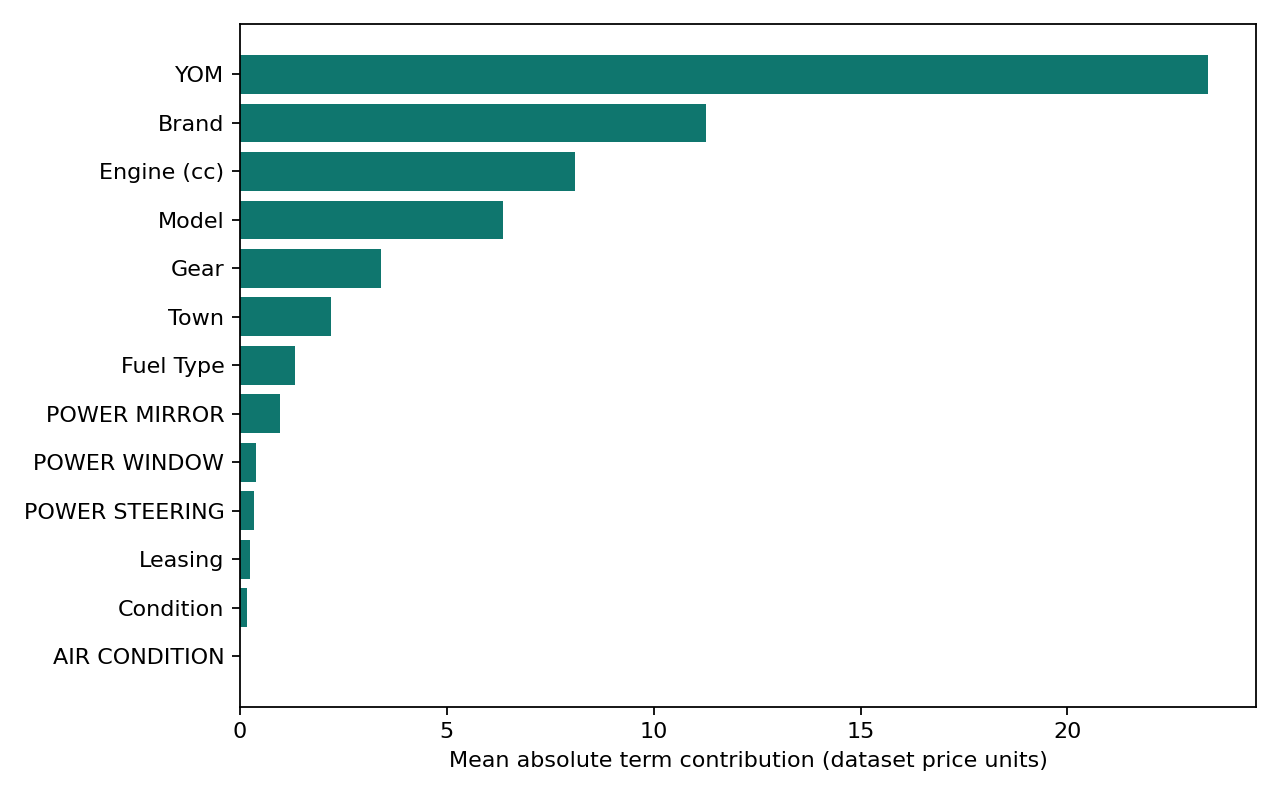

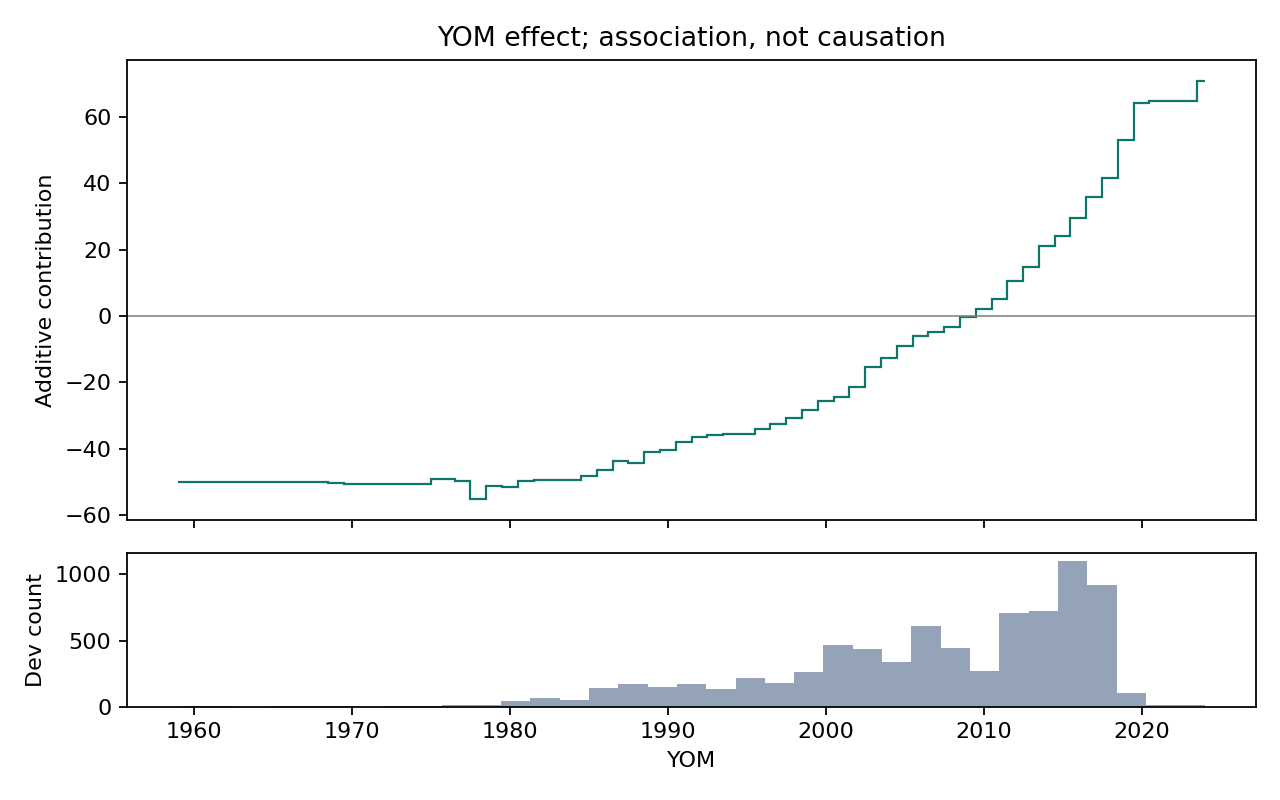

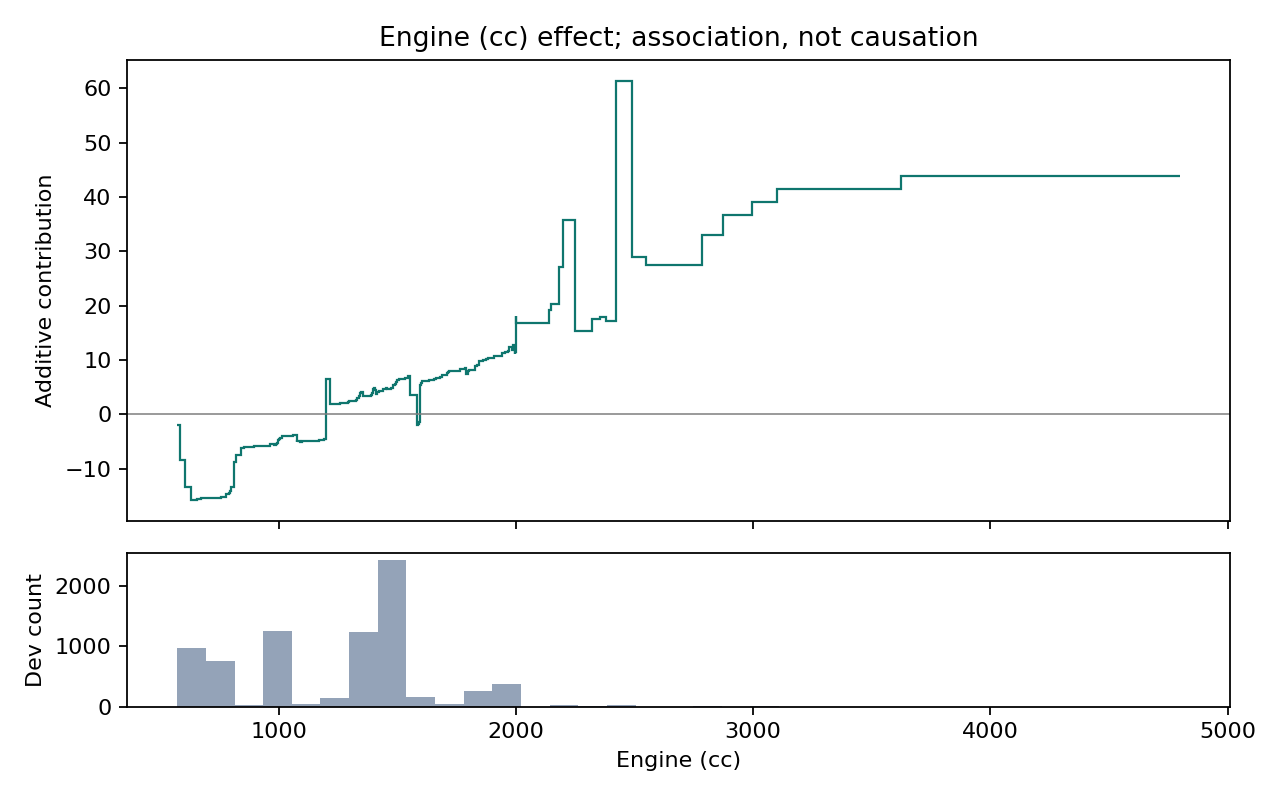

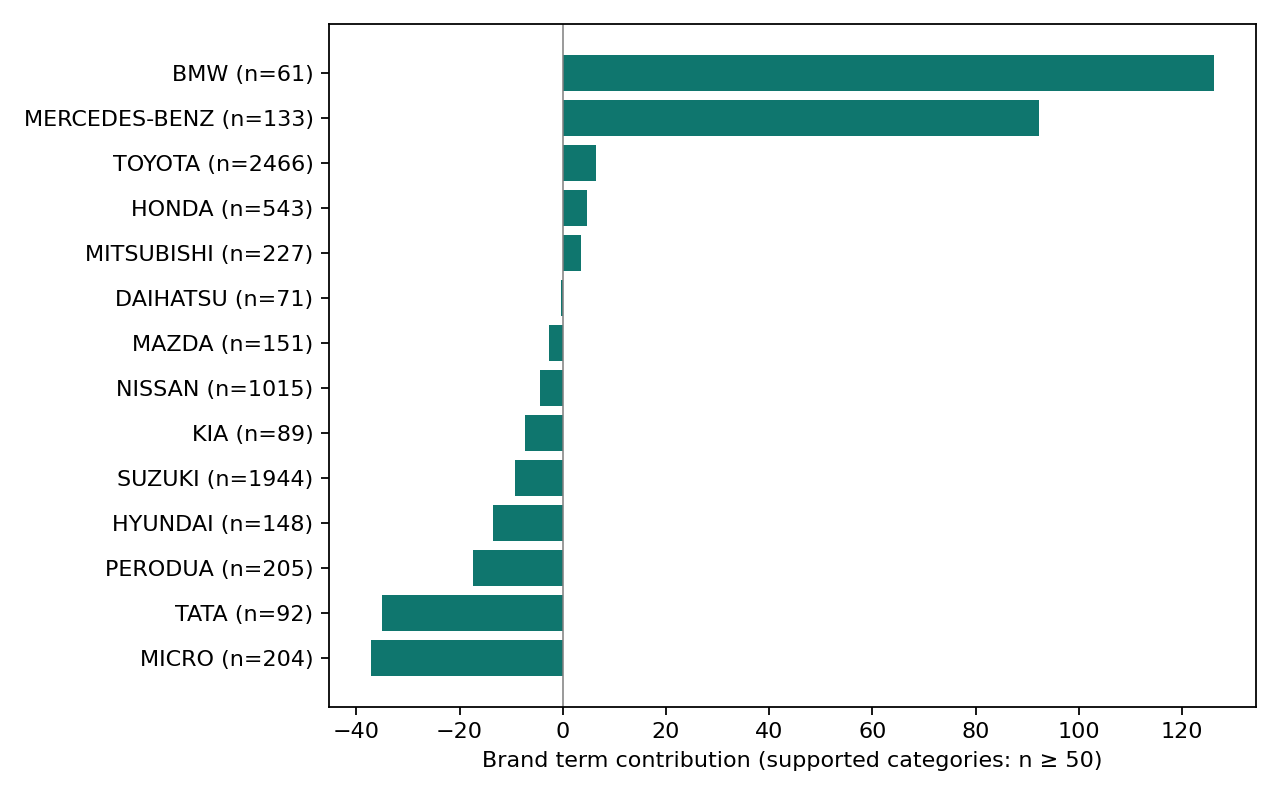

In [6]:
importance, local, comparison = explanations()
display(importance.round(4))
display(Image(filename=str(OUT/'figures/term_importance.png')))
display(Image(filename=str(OUT/'figures/year_effect.png')))
display(Image(filename=str(OUT/'figures/engine_effect.png')))
display(Image(filename=str(OUT/'figures/brand_effect.png')))

## 7 Local explanation
Before EBM error inspection, the protocol selected cleaned row 11, the same observation used in the historical demonstration. We calculate a new EBM prediction rather than copying the Random Forest result. Positive contributions raise the estimate above the intercept; negative contributions lower it. All thirteen terms are included in the numerical check. No clipping is used, because clipping would invalidate the additive identity.

For the 2018 Audi A3, the EBM intercept is 53.4420. Brand (+47.1135) and year (+41.5978) are the largest positive terms; the 1,000 cc engine contributes −4.8009. All terms together add 95.9622, giving **149.4042**, compared with the actual listing price 139.00. The absolute error is 10.4042. The historical RF prediction for this row remains 141.4569 and is a different model output.

row_id            1.100000e+01
actual            1.390000e+02
intercept         5.344196e+01
prediction        1.494042e+02
sum               1.494042e+02
sum_difference    2.842171e-14
dtype: float64

,term,value
0,Brand,47.11345
1,Model,8.24285
2,YOM,41.59779
3,Engine (cc),-4.80085
4,Gear,2.64900
5,Fuel Type,0.27604
6,Town,0.59906
7,Leasing,0.12911
8,Condition,-0.09076
9,AIR CONDITION,0.00633


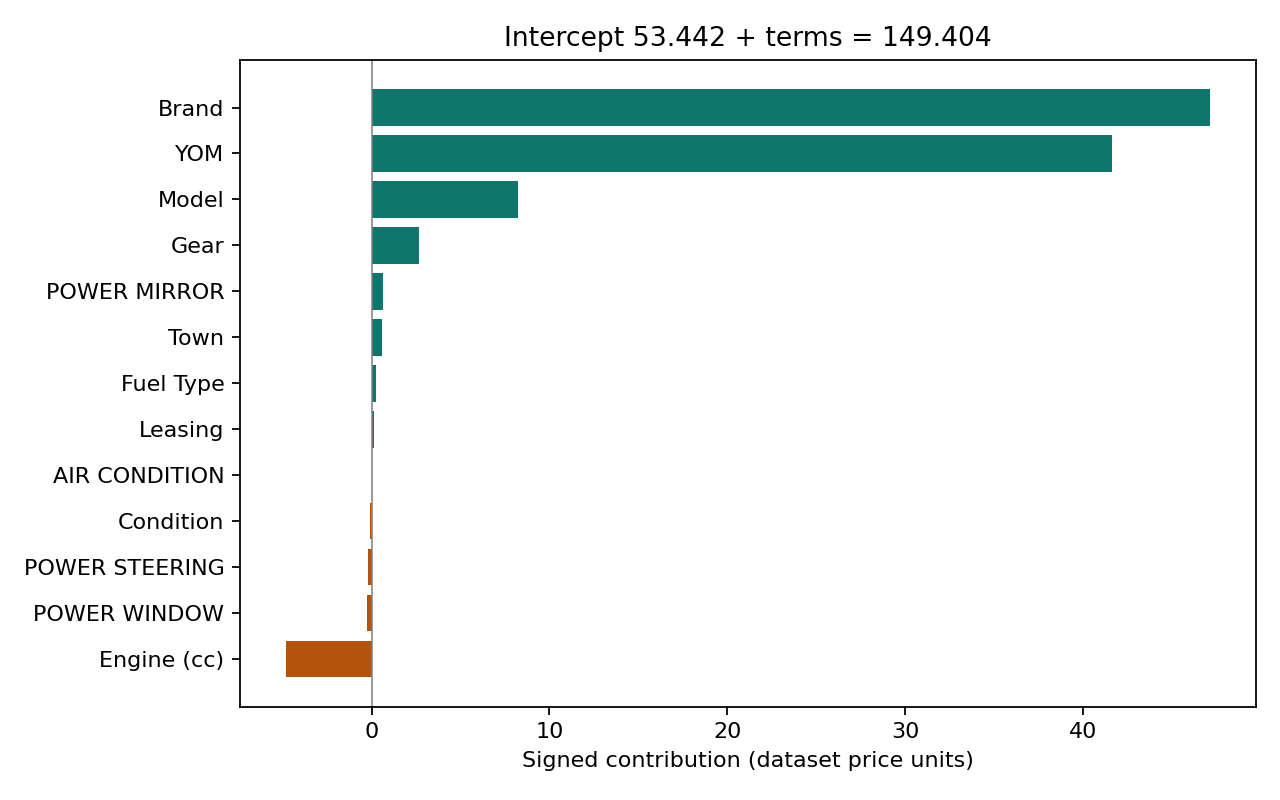

In [7]:
display(pd.Series({k:local[k] for k in ['row_id','actual','intercept','prediction','sum','sum_difference']}))
display(pd.DataFrame(local['terms']).round(5))
assert local['sum_difference'] < 1e-8
display(Image(filename=str(OUT/'figures/local_explanation.png')))

## 8 Comparison and critical discussion
The table keeps the historical accepted study separate from this subsequent extension. It is not a new joint six-model selection exercise. Random Forest remains the historical accuracy-selected winner. EBM is the focal new algorithm because it provides directly inspectable additive explanations, regardless of its ranking.

MAE measures typical absolute error, RMSE emphasizes large misses and R² compares against a constant test mean; R² is not an accuracy percentage. Fit times are measured locally at different times and are approximate cost comparisons. Serialized size is an artifact property, not total inference memory. Original RF permutation importance measures the MAE increase after shuffling an input; its scale cannot be equated with native EBM term importance.

EBM did not beat Ridge or any historical tree ensemble on MAE in this bounded study. RF holdout MAE was 4.9093 and Ridge was 8.4133, compared with EBM 9.7644. The additive EBM trades higher measured error for a directly decomposable prediction and a small serialized model (0.141 MiB versus RF 20.499 MiB). This does not prove that interpretability always requires worse accuracy. For the 20 holdout listings above 200 units, EBM MAE was 91.51 with mean residual +88.01, showing substantial underprediction. Further tuning based on this holdout would weaken the already limited evaluation claim.

,model,MAE,RMSE,R2,seconds,artifact_bytes,cv_mae,study
0,Median,27.8855,44.0346,-0.0602,0.0828,10809,28.3609,Historical accepted
1,Ridge,8.4133,21.4865,0.7476,0.2025,24296,8.5247,Historical accepted
2,Random Forest,4.9093,19.0170,0.8023,52.4291,21494573,5.6002,Historical accepted
3,XGBoost,5.9851,19.5078,0.7919,1.7530,1253150,6.3770,Historical accepted
4,CatBoost,6.5747,19.9406,0.7826,28.6563,3976585,6.8716,Historical accepted
5,EBM,9.7644,23.9079,0.6875,7.8701,147531,10.3020,Subsequent extension


,band,n,mae,mean_residual
0,"(0.0, 25.0]",433.0,8.3522,-1.2823
1,"(25.0, 50.0]",657.0,8.7367,-1.8923
2,"(50.0, 100.0]",694.0,7.4996,-3.0336
3,"(100.0, 200.0]",155.0,17.6576,3.1601
4,"(200.0, inf]",20.0,91.5139,88.0132


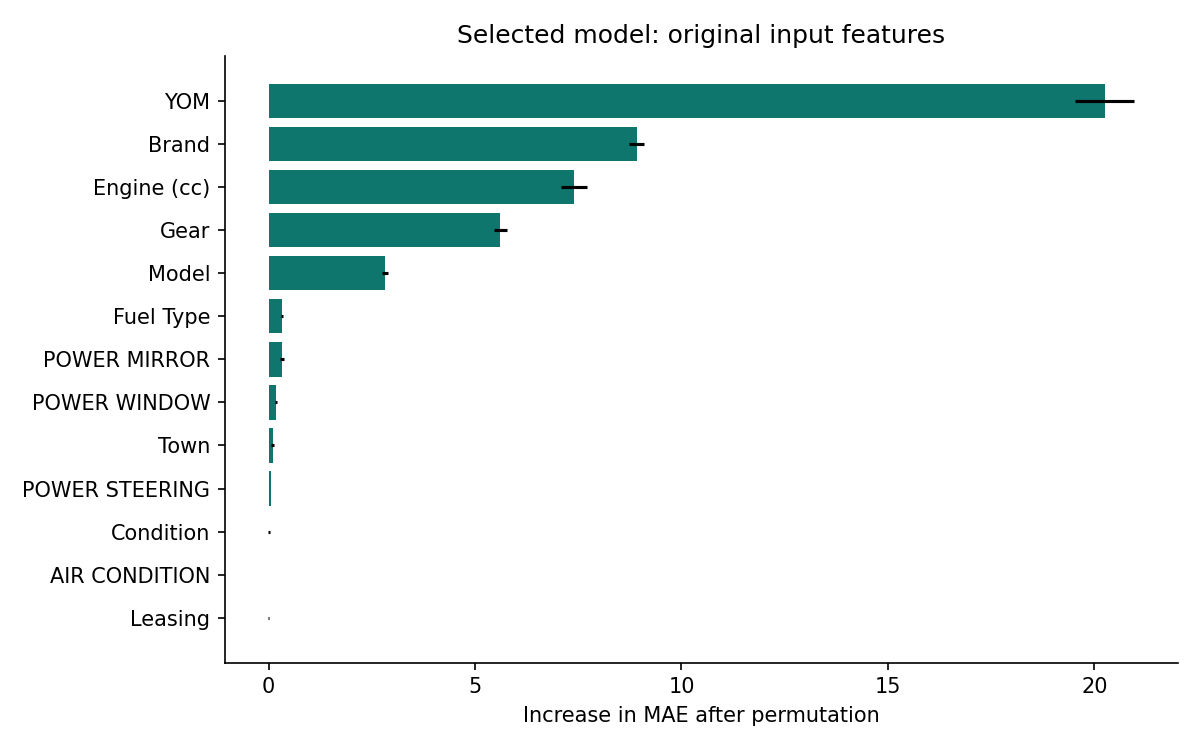

In [8]:
display(comparison.round(4))
display(pd.read_csv(OUT/'price_band_errors.csv').round(4))
display(Image(filename=str(ROOT/'results/accepted/figures/permutation_importance.png')))

## 9 Limitations and responsible use
These are historical advertisements, not verified transactions or current valuations. The original price currency scale is unconfirmed; results stay in dataset units. Expensive vehicles and rare categories can have large errors. Exact grouping cannot eliminate unrecorded vehicle identity, temporal leakage or near-duplicates. The inspected holdout and small fixed search limit claims of generalization or optimality. The additive model excludes interactions and may miss relationships captured by tree ensembles. A 2,000-round cap and internal group validation constrain training on this laptop.

No causal, fairness or calibrated uncertainty claim is supported. Town, brand and equipment can proxy social or market differences; subgroup error checks require sufficient support and cannot establish demographic fairness because demographic labels are absent. Predictions could mislead buyers or sellers if presented as authoritative prices. Use only as an educational explanation, retain data attribution and check redistribution rights before sharing data.

## References and acknowledgement
- Prasad Nirmal, *Sri Lankan Second Vehicle Car Price Dataset*, Kaggle version 3: https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset
- InterpretML, *Explainable Boosting Regressor API*: https://interpret.ml/docs/python/api/ExplainableBoostingRegressor.html
- InterpretML, *Explainable Boosting Machine*: https://interpret.ml/docs/ebm.html

AI assistance supported coding, documentation and verification. Actual local execution evidence is retained; the student should review and be able to explain the workflow, claims and limitations before submission.

The selected model and development/test result files are sealed after verification. The archived notebook under verification records the actual training execution; a later cached verification execution does not represent another search. Source code remains executable for a deliberately new run ID.